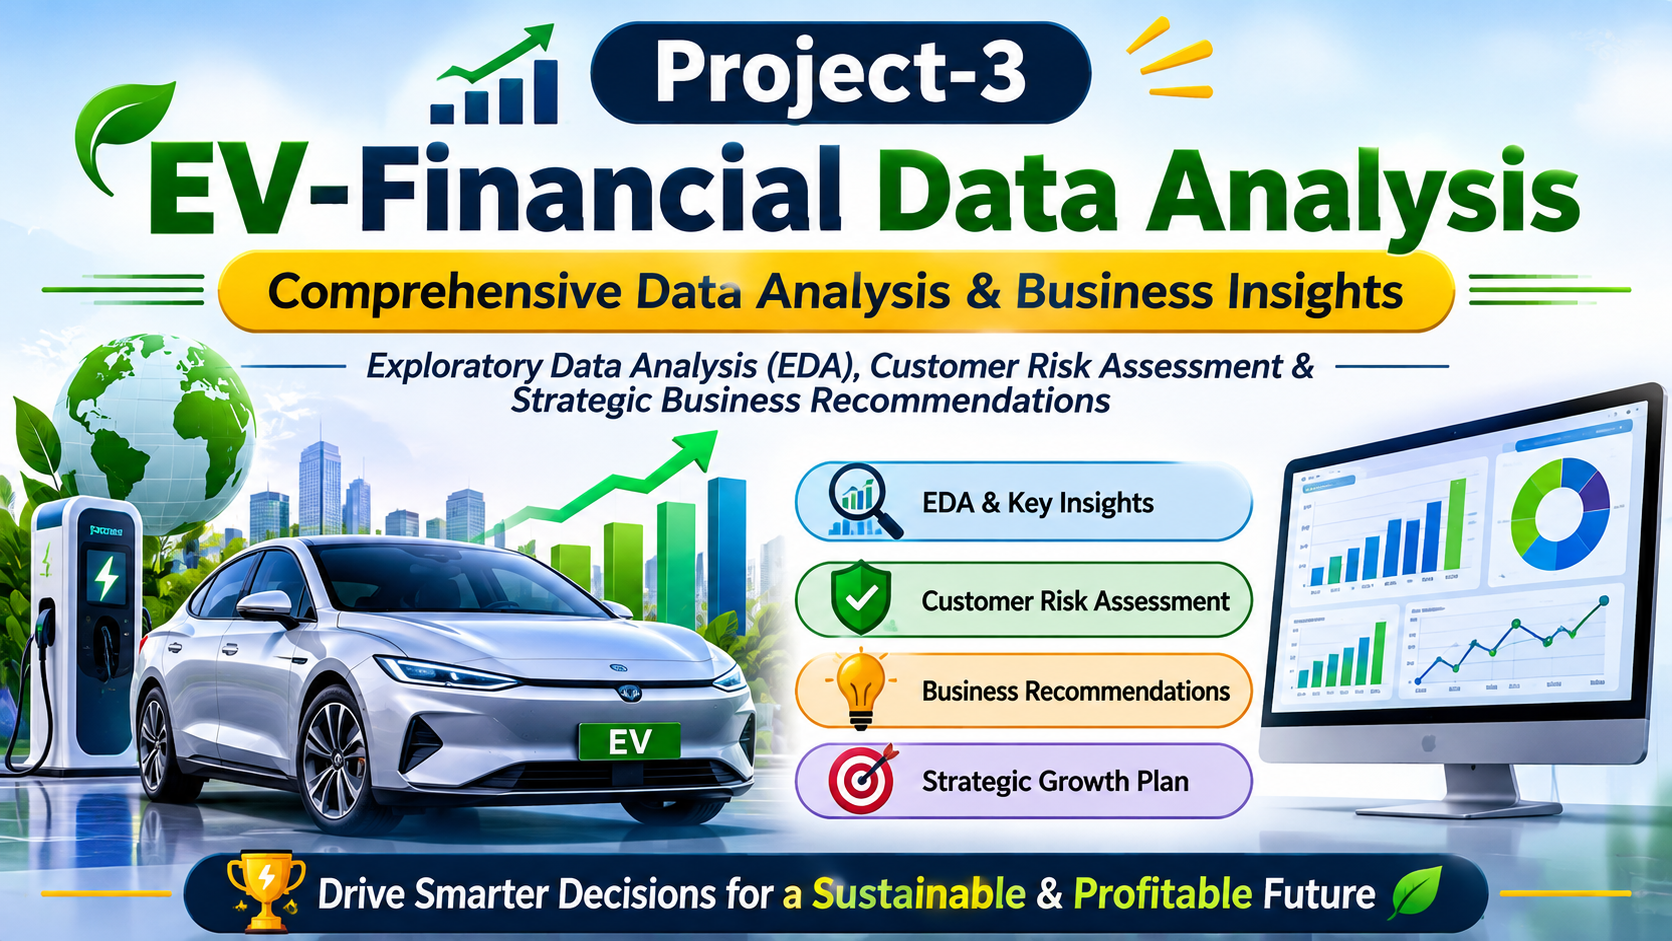

In [180]:
from IPython.display import display, HTML, Image
display(HTML("""<h1 style="text-align:center; color:#145A32;">🚗 Project-3: EV-Financial Data Analysis 📊</h1>
<h3 style="text-align:center; color:#2874A6;">📈 Comprehensive Data Analysis & Business Insights</h3>
<p style="text-align:center; color:#D68910;">🔍 EDA | 🛡️ Customer Risk Assessment |💡 Business Recommendations</p>"""))
display(Image(filename='ev_financial_project.png', width=900, height=100))


## About the Project

The **EV Financial Data Analysis** project focuses on analyzing electric vehicle (EV) loan applications to understand business performance, financial affordability, and credit risk. The main objective is to identify key factors influencing loan approval decisions, evaluate customers' repayment capacity, and assess financial risks associated with EV financing.

Using Python, Pandas, NumPy, and data visualization techniques, this project explores loan application data and generates meaningful insights to support better financial decision-making.

## Project Objectives

### 1. Business Performance Analysis
- Analyze total loan application volumes and approval rates.
- Calculate average loan amounts and approval percentages.
- Evaluate city-wise loan application performance.
- Identify cities with higher approval and rejection rates.

### 2. Financial Analysis
- Calculate EMI affordability based on customers' income.
- Analyze disposable income after monthly expenses and EMI payments.
- Evaluate down-payment ratios to understand customers' initial financial contribution.
- Measure overall loan exposure and financial commitments.

### 3. Credit Risk Analysis
- Compare loan rejection rates across different credit score categories.
- Analyze credit risk based on employment types.
- Evaluate the impact of previous loan defaults on approval decisions.
- Identify customer segments with higher credit risk.
- 
### 4. Customer Segmentation Analysis 👥📊
- Income-wise Segmentation 💰
- Credit Score-wise Segmentation 💳
- Employment-wise Segmentation 👨‍💼
- Overall Customer Risk Segmentation 🎯
  
### 5. City-wise & Regional Analysis 🏙️📊
- Which city receives the highest number of loan applications?
- Which city has the highest loan approval rate?
- Which city has the highest average loan amount?
- Which region demonstrates the best business performance?
- Which city has the highest loan rejection rate?

### 6. Final Business Recommendations & Conclusion 🚀📊
  Final Business Recommendations main purpose:
- Improve overall business performance.
- Identify the reasons behind loan rejections.
- Reduce financial risks.
- Target the right customers.
- Expand business operations in high-potential cities.
- Improve the company's overall profitability.

### 7. Overall Business Performance Summary 📊
### 8. Identify Business Problems 🔍
### 9. Business Recommendations 💡
- Improve EMI Affordability 💳
- Improve Credit Risk Management ⚠️
- Focus on Customer Segmentation 👥
- Improve Regional Business Performance 🏙️
- Improve Down Payment Strategy 💰
### Business Recommendation Priority Analysis 🎯

## Tools & Technologies
- **Python** – Data analysis and calculations.
- **Pandas & NumPy** – Data cleaning, manipulation, and analysis.
- **Matplotlib & Seaborn** – Data visualization.
- **Jupyter Notebook** – Exploratory Data Analysis (EDA).


In [133]:
### 🐍✨Phase -1 Import necessary python libraies and load data 

### 💻 Import Libraries 

In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor

### 📊Load and Explore Excel Data file 

In [135]:
ev_financial=pd.read_excel('ev_financing_analyst_dataset.xlsx')

### Fetching 5 records from the top of the DataFrame

In [136]:
ev_financial.head()

,Application_ID,City,Employment_Type,Vehicle_Price_INR,Down_Payment_INR,Loan_Amount_INR,Interest_Rate_Annual_Pct,Tenure_Months,Monthly_EMI_INR,Monthly_Income_INR,Monthly_Expenses_INR,Debt_to_Income_Ratio,Credit_Score,Prior_Loan_Default_Flag,Application_Decision,Application_Year,Down_Payment_Pct,Monthly_Disposable_Income_INR,EMI_to_Income_Pct
0,EVF001,Delhi,Private,1250000,200000,1050000,9.50,48,26330,95000,72000,0.82,720,0,Approved,2026,16.00,23000,27.70
1,EVF002,Mumbai,Private,1800000,300000,1500000,9.20,60,31350,110000,84000,0.76,755,0,Approved,2026,16.70,26000,28.50
2,EVF003,Bengaluru,Gig Worker,950000,100000,850000,11.50,48,22050,65000,52000,0.68,690,1,Approved with Conditions,2026,10.50,13000,33.90
3,EVF004,Pune,Private,1450000,250000,1200000,9.80,60,25450,88000,68000,0.79,735,0,Approved,2026,17.20,20000,28.90
4,EVF005,Hyderabad,Self-employed,2200000,400000,1800000,10.50,60,38650,150000,105000,0.72,710,0,Approved,2026,18.20,45000,25.80


In [137]:
### Fetching bottom five records from the table 

In [138]:
ev_financial.tail()

,Application_ID,City,Employment_Type,Vehicle_Price_INR,Down_Payment_INR,Loan_Amount_INR,Interest_Rate_Annual_Pct,Tenure_Months,Monthly_EMI_INR,Monthly_Income_INR,Monthly_Expenses_INR,Debt_to_Income_Ratio,Credit_Score,Prior_Loan_Default_Flag,Application_Decision,Application_Year,Down_Payment_Pct,Monthly_Disposable_Income_INR,EMI_to_Income_Pct
25,EVF026,Chennai,Private,1500000,250000,1250000,9.60,60,26500,90000,70000,0.82,755,0,Approved,2026,16.70,20000,29.40
26,EVF027,Delhi,Gig Worker,1050000,100000,950000,12.40,48,25200,62000,41000,0.65,660,1,Rejected,2026,9.50,21000,40.60
27,EVF028,Jaipur,Self-employed,1600000,250000,1350000,10.90,60,29300,85000,59000,0.71,700,0,Approved,2026,15.60,26000,34.50
28,EVF029,Kolkata,Private,1250000,200000,1050000,9.80,48,26400,80000,62000,0.79,735,0,Approved,2026,16.00,18000,33.00
29,EVF030,Ahmedabad,Gig Worker,900000,100000,800000,12.60,36,26500,60000,39000,0.62,650,1,Rejected,2026,11.10,21000,44.20


### Checking Data types of all columns

In [139]:
ev_financial.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Application_ID                 30 non-null     object 
 1   City                           30 non-null     object 
 2   Employment_Type                30 non-null     object 
 3   Vehicle_Price_INR              30 non-null     int64  
 4   Down_Payment_INR               30 non-null     int64  
 5   Loan_Amount_INR                30 non-null     int64  
 6   Interest_Rate_Annual_Pct       30 non-null     float64
 7   Tenure_Months                  30 non-null     int64  
 8   Monthly_EMI_INR                30 non-null     int64  
 9   Monthly_Income_INR             30 non-null     int64  
 10  Monthly_Expenses_INR           30 non-null     int64  
 11  Debt_to_Income_Ratio           30 non-null     float64
 12  Credit_Score                   30 non-null     int64

## 🧹 Phase 2: Data Cleaning Process

1. 🔍 **Check Duplicate Records** – Identify duplicate records in the DataFrame.
2. 🩹 **Handle Missing Values** – Identify and manage missing or null values.
3. 📊 **Detect and Remove Outliers** – Identify and handle outliers in the dataset.
4. 🗑️ **Remove Irrelevant Data** – Eliminate unnecessary or irrelevant information.
5. 🔠 **Standardize Capitalization** – Maintain consistent capitalization across text values.
6. 🔄 **Convert Data Types** – Convert columns to the appropriate data types. 
7. 🧾 **Clean Formatting** – Ensure consistent formatting throughout the dataset.
8. 🌐 **Language Translation** – Translate text into the required language where necessary.
9. 🛠️ **Fix Errors** – Correct spelling mistakes, inconsistent values, and data entry errors.

In [140]:
# 1.🔍 Check Duplicate Records – Identify duplicate records in the DataFrame.
print('No. of duplicate records found in DataFrame:',ev_financial.duplicated().sum())


No. of duplicate records found in DataFrame: 0


In [141]:
# 🩹 Handle Missing Values – Identify and manage missing or null values.
print('Check missing values from every columns:')
ev_financial.isnull().sum()

print("No missing values found")

Check missing values from every columns:
No missing values found


### Phase-3 Initiating Data Analysis and Exploratory Data Analysis (EDA)

### Business Performance Analysis
In this analysis we should check main 4 important KPIs for checking the business performance
- Findout application volumes 📋
- Loan Approval Rates ✅
- Average Loan Amount 💰
- City-wise Performance 🏙️


### Find out application Volumes 📋
Business Question: How many customers are apply for EV loan?

In [142]:
total_applications = len(ev_financial)

print("Total Applications for EV Loan:", total_applications)

Total Applications for EV Loan: 30


In [143]:
print('City wise Loan application:')
city_applications = ev_financial['City'].value_counts()
print(city_applications)

City wise Loan application:
City
Delhi        4
Mumbai       3
Bengaluru    3
Pune         3
Hyderabad    3
Chennai      3
Jaipur       3
Kolkata      3
Ahmedabad    3
Lucknow      2
Name: count, dtype: int64


### Application Approval \ Rejected Rate calculate 

In [144]:
# Count approved applications
approved = ev_financial[
    ev_financial['Application_Decision'] == 'Approved'
].shape[0]

# Count approved with conditions
approval_with_condition = ev_financial[ev_financial['Application_Decision'] == 'Approved with Conditions'].shape[0]

# Count rejected application
rejected = ev_financial[ev_financial['Application_Decision'] == 'Rejected'].shape[0]


# Total applications
total = len(ev_financial)

# Calculate percentages
approval_rate = (approved / total) * 100

approval_with_condition_rate = (approval_with_condition / total) * 100

rejected = (rejected / total) * 100

# Print results
print("Approval Rate:", round(approval_rate, 2), "%")
print("Approved with Conditions Rate:",
      round(approval_with_condition_rate, 2), "%")

print("Rejected Rate:", round(rejected, 2), "%")

Approval Rate: 70.0 %
Approved with Conditions Rate: 20.0 %
Rejected Rate: 10.0 %


### Average Loan Amount Analysis 💰

In [145]:
average_loan = ev_financial['Loan_Amount_INR'].mean()

print("Average Loan Amount:", average_loan)

Average Loan Amount: 1190000.0


### City-wise Performance Analysis 🏙️

In [146]:
# Float formatting (scientific notation remove)
pd.options.display.float_format = '{:,.2f}'.format

city_performance = ev_financial.groupby('City').agg(

    Total_Applications=('Application_ID', 'count'),

    Approved=('Application_Decision',
        lambda x: x.isin([
            'Approved',
            'Approved with Conditions'
        ]).sum()),

    Rejected=('Application_Decision',
        lambda x: (x == 'Rejected').sum()),

    Average_Loan_Amount=('Loan_Amount_INR', 'mean')

)

city_performance['Approval_Rate'] = (
    city_performance['Approved'] /
    city_performance['Total_Applications']
) * 100

city_performance

,Total_Applications,Approved,Rejected,Average_Loan_Amount,Approval_Rate
City,,,,,
Ahmedabad,3,2,1,"1,250,000.00",66.67
Bengaluru,3,3,0,"1,200,000.00",100.00
Chennai,3,3,0,"1,033,333.33",100.00
Delhi,4,3,1,"1,155,000.00",75.00
Hyderabad,3,3,0,"1,483,333.33",100.00
Jaipur,3,3,0,"1,183,333.33",100.00
Kolkata,3,2,1,"1,050,000.00",66.67
Lucknow,2,2,0,"875,000.00",100.00
Mumbai,3,3,0,"1,466,666.67",100.00


### Business Performance-Data Visualization 📊

### City-wise Application Volume

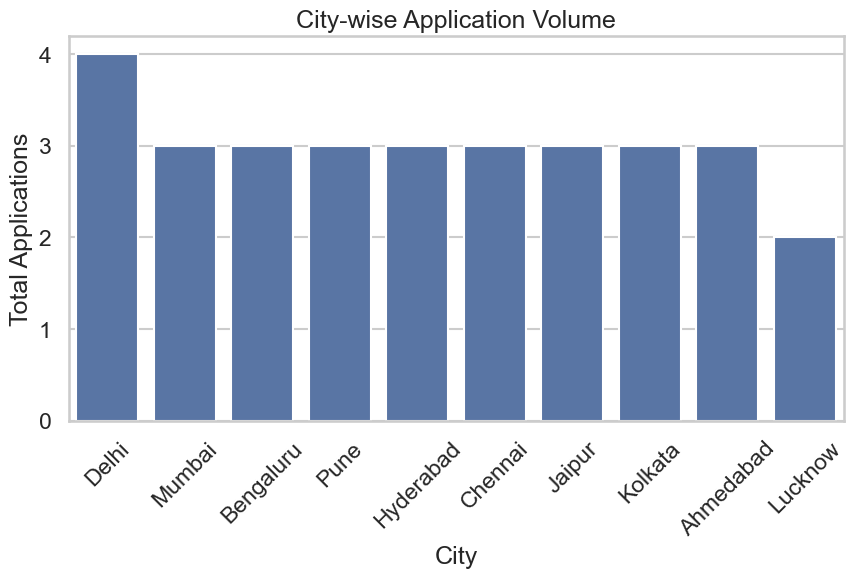

In [147]:
plt.figure(figsize=(10,5))

sns.countplot(data=ev_financial, x='City',order=ev_financial['City'].value_counts().index)

plt.title('City-wise Application Volume')
plt.xlabel('City')
plt.ylabel('Total Applications')
plt.xticks(rotation=45)

plt.show()

### City-wise Approval Rate

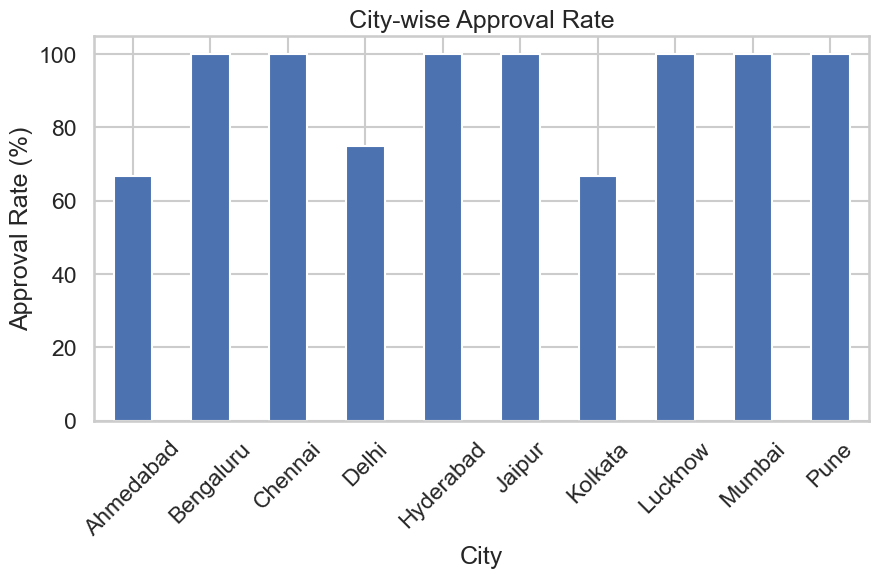

In [148]:
city_performance['Approval_Rate'].plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('City-wise Approval Rate')
plt.xlabel('City')
plt.ylabel('Approval Rate (%)')
plt.xticks(rotation=45)
plt.show()

### City-wise Average Loan Amount

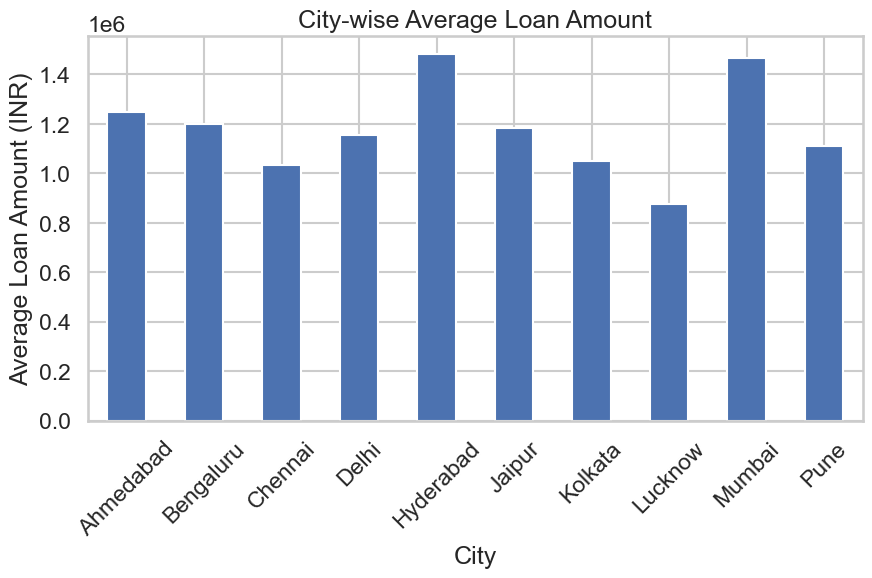

In [149]:
city_performance['Average_Loan_Amount'].plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('City-wise Average Loan Amount')
plt.xlabel('City')
plt.ylabel('Average Loan Amount (INR)')
plt.xticks(rotation=45)
plt.show()

### 💡 Conclusion: After Performed Business Analysis

 After completing analysis  the project report found following important things:
1. Application Volume: Delhi mein sabse zyada 4 loan applications receive hue.
2. Approval Rate: Overall approval rate 90% hai, conditional approvals ko include karne par.
3. Average Loan: Average loan amount ₹11.90 lakh hai.
4. Best City: Hyderabad mein highest average loan amount ₹14.83 lakh hai aur 100% approval rate hai.
5. Improvement Area: Ahmedabad aur Kolkata mein approval rate 66.7% hai. In cities mein loan rejection reasons investigate karne chahiye.

### 2. Financial data Analysis 💰📊
EV Financing Analyst Dataset mein Financial Analysis karne ke liye hum 4 important areas cover karenge:
- EMI Affordability – Customer apni monthly income se EMI pay kar sakta hai ya nahi.
- Disposable Income – Monthly expenses ke baad customer ke paas kitna paisa bachta hai.
- Down-Payment Ratio – Customer vehicle purchase mein kitna percentage khud pay kar raha hai.
- Loan Exposure – Company ne total kitne amount ka loan finance kiya hai ya karne ka proposal diya hai.

### EMI Affordability Analysis 💳 
Kya customer apni monthly disposable income se loan ki EMI afford kar sakta hai

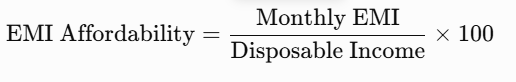


In [150]:
ev_financial['EMI_Affordability_Pct'] = (
    ev_financial['Monthly_EMI_INR'] /
    ev_financial['Monthly_Disposable_Income_INR']
) * 100

ev_financial[[
    'Application_ID',
    'Monthly_Disposable_Income_INR',
    'Monthly_EMI_INR',
    'EMI_Affordability_Pct'
]]

,Application_ID,Monthly_Disposable_Income_INR,Monthly_EMI_INR,EMI_Affordability_Pct
0,EVF001,23000,26330,114.48
1,EVF002,26000,31350,120.58
2,EVF003,13000,22050,169.62
3,EVF004,20000,25450,127.25
4,EVF005,45000,38650,85.89
5,EVF006,17000,23820,140.12
6,EVF007,13000,23900,183.85
7,EVF008,22000,26100,118.64
8,EVF009,21000,28300,134.76
9,EVF010,35000,35600,101.71


### Affordability status check 

In [151]:

ev_financial['EMI_Status'] = np.where(
    ev_financial['Monthly_EMI_INR'] <=
    ev_financial['Monthly_Disposable_Income_INR'],
    'Affordable',
    'Not Affordable'
)

ev_financial['EMI_Status'].value_counts()

EMI_Status
Not Affordable    27
Affordable         3
Name: count, dtype: int64

### EMI Affordability- Data Visulization

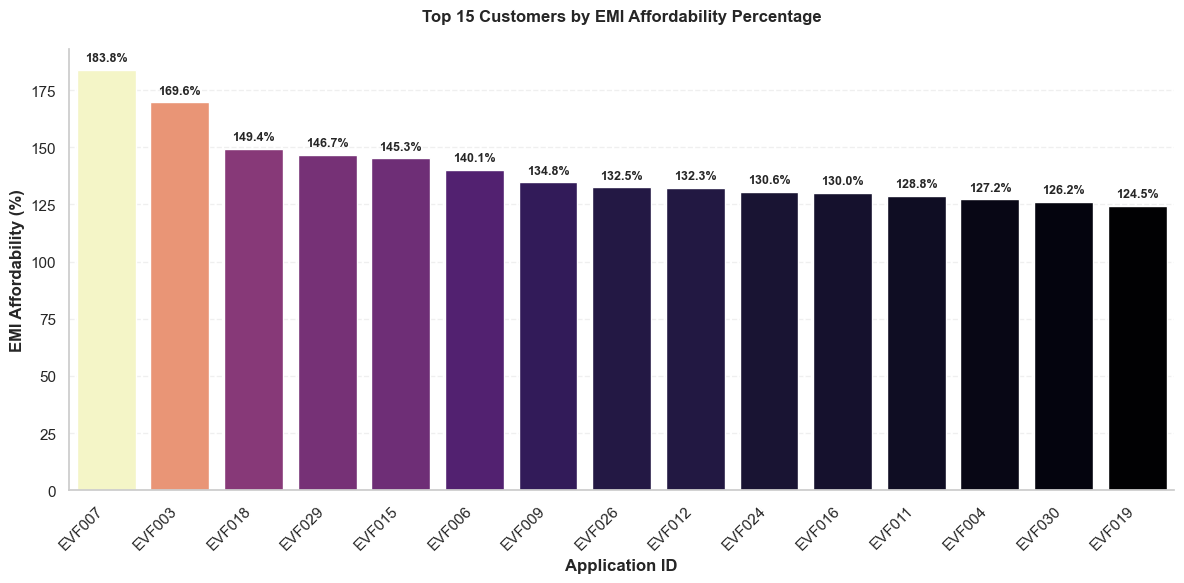

In [152]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate EMI Affordability Percentage
ev_financial['EMI_Affordability_Pct'] = (
    ev_financial['Monthly_EMI_INR'] /
    ev_financial['Monthly_Disposable_Income_INR']
) * 100

# Select top 15 customers
plot_data = ev_financial.nlargest(
    15, 'EMI_Affordability_Pct'
)

# Professional theme
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

# Create bar plot
ax = sns.barplot(
    data=plot_data,
    x='Application_ID',
    y='EMI_Affordability_Pct',
    hue='EMI_Affordability_Pct',
    palette='magma',
    legend=False
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=4,
        fontsize=9,
        fontweight='bold'
    )

# Titles and labels
plt.title(
    'Top 15 Customers by EMI Affordability Percentage',
    fontsize=12,
    fontweight='bold',
    pad=20
)

plt.xlabel('Application ID', fontsize=12, fontweight='bold')
plt.ylabel('EMI Affordability (%)', fontsize=12, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.grid(axis='x', visible=False)

sns.despine()
plt.tight_layout()
plt.show()


### Disposable Income Analysis 💵
Customer ke paas monthly expenses pay karne ke baad kitna paisa bachta hai?

Formula:
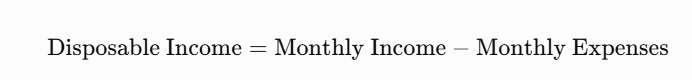

In [153]:
ev_financial['Disposable_Income'] = (
    ev_financial['Monthly_Income_INR'] -
    ev_financial['Monthly_Expenses_INR']
)

print("Average Disposable Income:",
      ev_financial['Disposable_Income'].mean())

print("Minimum Disposable Income:",
      ev_financial['Disposable_Income'].min())

print("Maximum Disposable Income:",
      ev_financial['Disposable_Income'].max())

Average Disposable Income: 24233.333333333332
Minimum Disposable Income: 13000
Maximum Disposable Income: 48000


### Disposable Income Data Plot

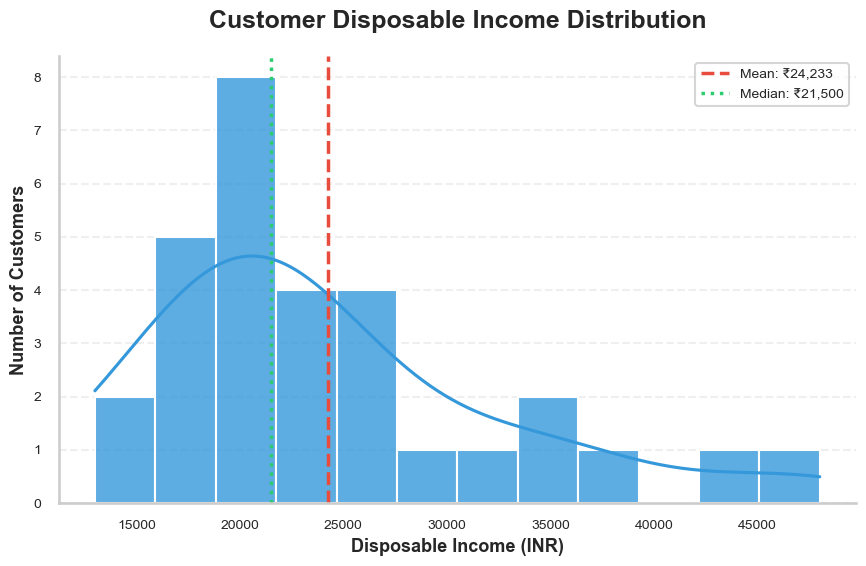

In [154]:

import matplotlib.pyplot as plt
import seaborn as sns

# Professional theme
sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(9, 6))

# Create histogram with KDE
ax = sns.histplot(
    data=ev_financial,
    x='Disposable_Income',
    bins=12,
    kde=True,
    color='#3498DB',
    edgecolor='white',
    linewidth=1.5,
    alpha=0.8
)

# Calculate mean and median
mean_income = ev_financial['Disposable_Income'].mean()
median_income = ev_financial['Disposable_Income'].median()

# Add reference lines
plt.axvline(
    mean_income,
    color='#E74C3C',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: ₹{mean_income:,.0f}'
)

plt.axvline(
    median_income,
    color='#2ECC71',
    linestyle=':',
    linewidth=2.5,
    label=f'Median: ₹{median_income:,.0f}'
)

# Titles and labels
plt.title(
    'Customer Disposable Income Distribution',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.xlabel('Disposable Income (INR)', fontsize=13, fontweight='bold')
plt.ylabel('Number of Customers', fontsize=13, fontweight='bold')

# Styling
plt.legend(fontsize=10, frameon=True)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.grid(axis='x', visible=False)

sns.despine()
plt.tight_layout()
plt.show()


### Down-Payment Ratio Analysis 🚗
Customer vehicle purchase karne ke liye kitna percentage amount khud pay kar raha hai?

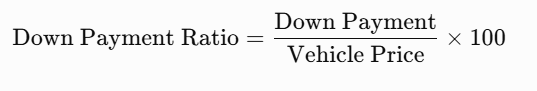

In [155]:
ev_financial['Down_Payment_Ratio'] = (
    ev_financial['Down_Payment_INR'] /
    ev_financial['Vehicle_Price_INR']
) * 100

print("Average Down Payment Ratio:",
      ev_financial['Down_Payment_Ratio'].mean())

Average Down Payment Ratio: 14.697848951023271


### Data Visulization-Down Payment Ratio

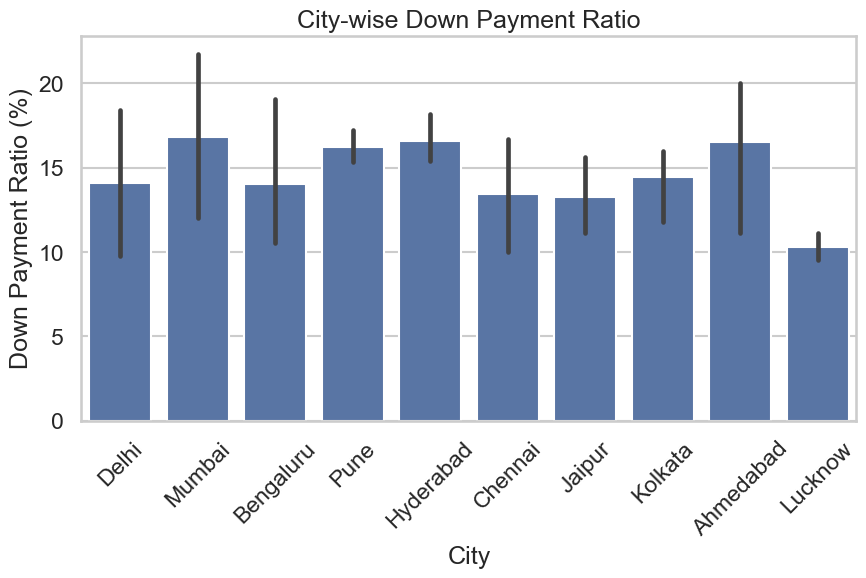

In [156]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=ev_financial,
    x='City',
    y='Down_Payment_Ratio'
)

plt.title('City-wise Down Payment Ratio')
plt.xlabel('City')
plt.ylabel('Down Payment Ratio (%)')
plt.xticks(rotation=45)

plt.show()

### Loan Exposure Analysis 🏦
Company total kitne amount ka loan finance kar rahi hai?
Loan Exposure calculate karne ke liye total loan amount ka sum nikalenge.

In [157]:
total_loan_exposure = (
    ev_financial['Loan_Amount_INR'].sum()
)

average_loan_exposure = (
    ev_financial['Loan_Amount_INR'].mean()
)

print("Total Loan Exposure:",
      total_loan_exposure)

print("Average Loan Exposure:",
      average_loan_exposure)

Total Loan Exposure: 35700000
Average Loan Exposure: 1190000.0


### Application Decision ke according Loan Exposure:

In [158]:
loan_exposure = ev_financial.groupby(
    'Application_Decision'
)['Loan_Amount_INR'].agg(
    ['count', 'sum', 'mean']
)

loan_exposure.columns = [
    'Applications',
    'Total_Loan_Exposure',
    'Average_Loan'
]

loan_exposure

,Applications,Total_Loan_Exposure,Average_Loan
Application_Decision,,,
Approved,21,27630000,"1,315,714.29"
Approved with Conditions,6,5570000,"928,333.33"
Rejected,3,2500000,"833,333.33"


### EMI vs Disposable Income Visualization 📊
Ye graph batayega ki customer ki EMI uski disposable income se kitni zyada ya kam hai.

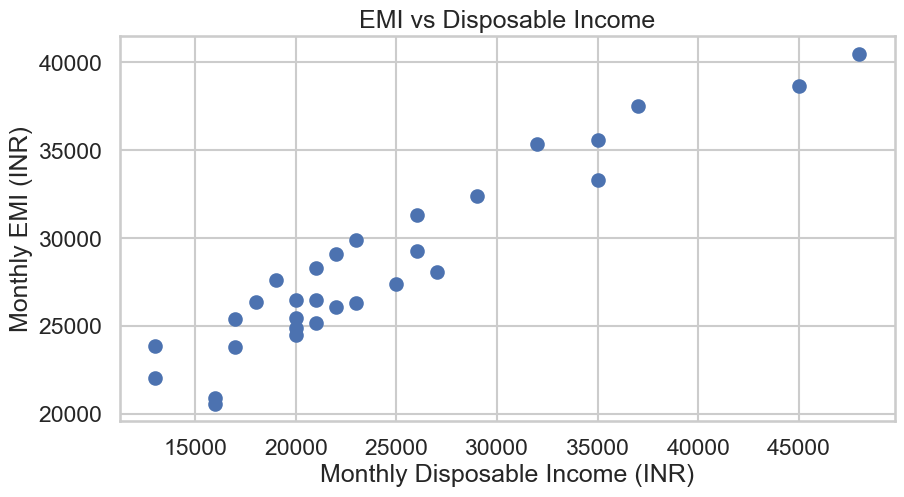

In [159]:
plt.figure(figsize=(10,5))

plt.scatter(
    ev_financial['Monthly_Disposable_Income_INR'],
    ev_financial['Monthly_EMI_INR']
)

plt.xlabel('Monthly Disposable Income (INR)')
plt.ylabel('Monthly EMI (INR)')
plt.title('EMI vs Disposable Income')

plt.show()

### Conclusion:
Final Business Insights 💡
Project report mein ye findings mention kar sakte hain:
1. EMI Affordability: 30 mein se 27 customers ki EMI disposable income se higher hai.
2. Disposable Income: Average disposable income ₹24,233 hai.
3. Down Payment: Customers average vehicle price ka 14.69% down payment kar rahe hain.
4. Loan Exposure: Total proposed loan exposure ₹3.57 crore hai.
5. Financial Risk: EMI affordability ek major concern hai. Loan approval se pehle customer ki repayment capacity carefully evaluate karni chahiye.

### 3. Credit Risk Analysis 💳📊
EV Financing Analyst Dataset mein Credit Risk Analysis ka main purpose hai identify karna ki kaunse customers mein loan rejection ka risk zyada hai.

Is analysis mein hum 3 important factors compare karenge:
1. Credit Score – Low credit score wale customers ka rejection rate kitna hai?
2. Employment Type – Private, Self-employed aur Gig Workers mein kis category ka rejection rate zyada hai?
3. Previous Loan Defaults – Jin customers ne pehle loan default kiya hai, unka rejection rate kitna hai?

### Credit Score-wise Rejection Rate Analysis 📉

In [160]:
ev_financial['Credit_Score_Category'] = pd.cut(
    ev_financial['Credit_Score'],
    bins=[0, 699, 749, 850],
    labels=['Low', 'Medium', 'High']
)

credit_analysis = ev_financial.groupby(
    'Credit_Score_Category',
    observed=False
).agg(
    Total_Applications=('Application_ID', 'count'),

    Rejected=('Application_Decision',
              lambda x: (x == 'Rejected').sum())
)

credit_analysis['Rejection_Rate'] = (
    credit_analysis['Rejected'] /
    credit_analysis['Total_Applications']
) * 100

credit_analysis

,Total_Applications,Rejected,Rejection_Rate
Credit_Score_Category,,,
Low,10,3,30.00
Medium,15,0,0.00
High,5,0,0.00


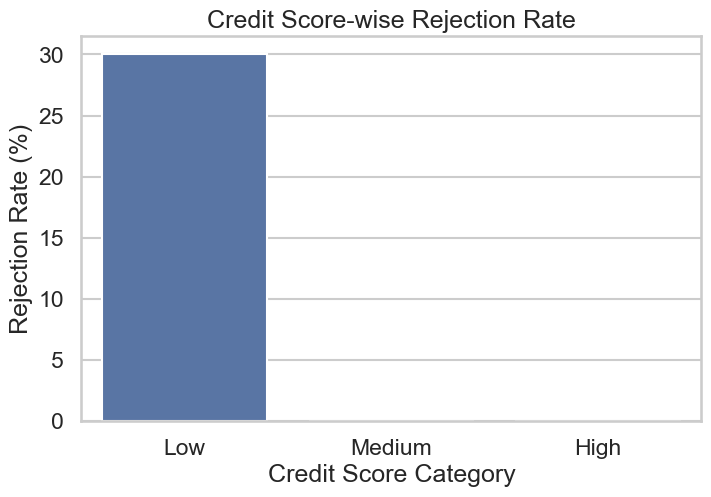

In [161]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=credit_analysis.reset_index(),
    x='Credit_Score_Category',
    y='Rejection_Rate'
)

plt.title('Credit Score-wise Rejection Rate')
plt.xlabel('Credit Score Category')
plt.ylabel('Rejection Rate (%)')

plt.show()

### Employment Type-wise Rejection Analysis 👨‍💼

### Business Questions:
- Private employees ka rejection rate kitna hai?
- Self-employed customers ka rejection rate kitna hai?
- Gig Workers mein loan rejection zyada hai ya kam?

In [162]:
employment_analysis = ev_financial.groupby(
    'Employment_Type'
).agg(
    Total_Applications=('Application_ID', 'count'),

    Rejected=('Application_Decision',
              lambda x: (x == 'Rejected').sum())
)

employment_analysis['Rejection_Rate'] = (
    employment_analysis['Rejected'] /
    employment_analysis['Total_Applications']
) * 100

employment_analysis

,Total_Applications,Rejected,Rejection_Rate
Employment_Type,,,
Gig Worker,8,3,37.50
Private,14,0,0.00
Self-employed,8,0,0.00


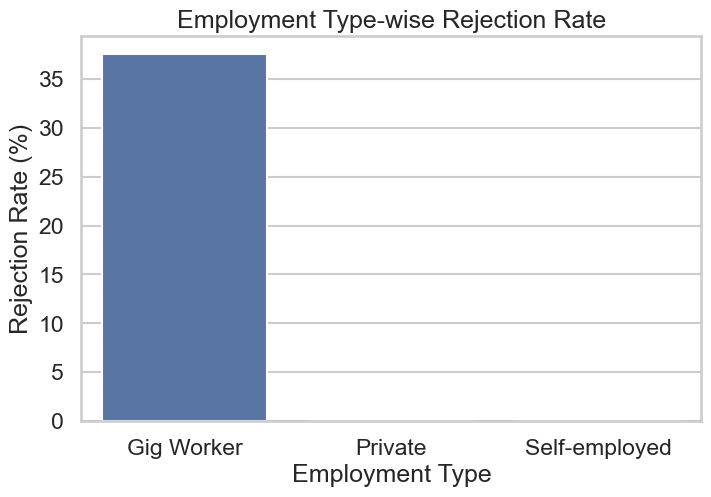

In [163]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=employment_analysis.reset_index(),
    x='Employment_Type',
    y='Rejection_Rate'
)

plt.title('Employment Type-wise Rejection Rate')
plt.xlabel('Employment Type')
plt.ylabel('Rejection Rate (%)')

plt.show()

Business Insight 💡: Gig Workers ka rejection rate sabse zyada 37.5% hai. Company ko Gig Workers ki income stability aur repayment capacity carefully evaluate karni chahiye.

### Previous Loan Defaults Analysis ⚠️

### Business Questions:
- Jin customers ne pehle loan default kiya hai, unka rejection rate kitna hai?
- Jin customers ka previous default nahi hai, unka rejection rate kitna hai?
- Previous loan default ka loan decision par kya impact hai?
Dataset mein Prior_Loan_Default_Flag column available hai:
- 1 = Previous Loan Default
- 0 = No Previous Loan Default

In [164]:
default_analysis = ev_financial.groupby(
    'Prior_Loan_Default_Flag'
).agg(
    Total_Applications=('Application_ID', 'count'),

    Rejected=('Application_Decision',
              lambda x: (x == 'Rejected').sum())
)

default_analysis['Rejection_Rate'] = (
    default_analysis['Rejected'] /
    default_analysis['Total_Applications']
) * 100

default_analysis.index = [
    'No Previous Default',
    'Previous Default'
]

default_analysis

,Total_Applications,Rejected,Rejection_Rate
No Previous Default,22,0,0.00
Previous Default,8,3,37.50


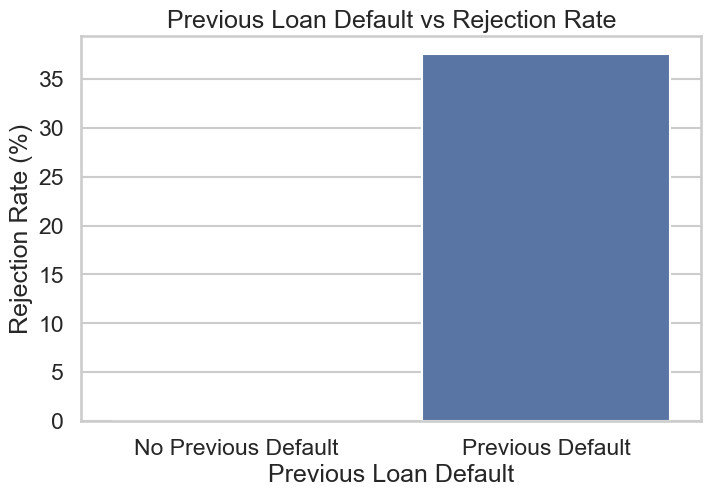

In [165]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=default_analysis.reset_index(),
    x='index',
    y='Rejection_Rate'
)

plt.title('Previous Loan Default vs Rejection Rate')
plt.xlabel('Previous Loan Default')
plt.ylabel('Rejection Rate (%)')

plt.show()

Business Insight 💡: Previous loan default wale customers mein rejection rate 37.5% hai, jabki no-default group mein 0% hai. Previous repayment history credit risk assessment ka important factor hai.

### Combined Credit Risk Analysis 📊
Ab thino factors ko ek saath compare karenge, taaki pata chale ki sabse zyada rejection kis category mein hai.

In [166]:
risk_factors = pd.DataFrame({

    'Credit Score': [
        credit_analysis.loc['Low', 'Rejection_Rate'],
        credit_analysis.loc['Medium', 'Rejection_Rate'],
        credit_analysis.loc['High', 'Rejection_Rate']
    ],

    'Employment Type': [
        employment_analysis.loc['Gig Worker', 'Rejection_Rate'],
        employment_analysis.loc['Private', 'Rejection_Rate'],
        employment_analysis.loc['Self-employed', 'Rejection_Rate']
    ],

    'Previous Default': [
        default_analysis.loc['Previous Default', 'Rejection_Rate'],
        default_analysis.loc['No Previous Default', 'Rejection_Rate'],
        np.nan
    ]

}, index=['High Risk Group', 'Other Group 1', 'Other Group 2'])

risk_factors

,Credit Score,Employment Type,Previous Default
High Risk Group,30.00,37.50,37.50
Other Group 1,0.00,0.00,0.00
Other Group 2,0.00,0.00,NaN


### Final Business Insights 💡
 project report mein ye findings likh sakte hain:
 
1. Credit Score Risk: Low credit score customers ka rejection rate 30% hai.
2. Employment Risk: Gig Workers mein rejection rate highest 37.5% hai.
3. Previous Default Risk: Previous loan default wale customers ka rejection rate 37.5% hai.
4. Private Employees: Private employees aur self-employed groups mein koi application reject nahi hui.
5. Risk Management: Loan approval se pehle credit score, employment stability aur previous repayment history check karna important hai.

### 4: Customer Segmentation Analysis 👥📊

Customer segmentation Analysis me customers ko unki financial condition, credit score, income aur employment ke basis par different groups mein divide karna.
Is analysis mein hum 4 important segments banayenge:
1. Income-wise Segmentation 💰
2. Credit Score-wise Segmentation 💳
3. Employment-wise Segmentation 👨‍💼
4. Overall Customer Risk Segmentation 🎯

### Income-wise Customer Segmentation 💰
Business Questions:
- Kitne customers Low Income category mein hain?
- Kitne customers Middle Income category mein hain?
- Kitne customers High Income category mein hain?
- Kis income group ka average loan amount highest hai?

In [167]:
# Customers have low Income category
ev_financial['Income_Segment'] = pd.cut(
    ev_financial['Monthly_Income_INR'],
    bins=[0, 70000, 100000, float('inf')],
    labels=['Low Income', 'Middle Income', 'High Income']
)

income_analysis = ev_financial.groupby(
    'Income_Segment',
    observed=False
).agg(
    Total_Customers=('Application_ID', 'count'),

    Average_Income=('Monthly_Income_INR', 'mean'),

    Average_Loan=('Loan_Amount_INR', 'mean')
)

income_analysis

,Total_Customers,Average_Income,Average_Loan
Income_Segment,,,
Low Income,9,"62,555.56","880,000.00"
Middle Income,13,"83,153.85","1,121,538.46"
High Income,8,"134,375.00","1,650,000.00"


### Data Visulization of customer income Category

C:\Users\AMBIKA\AppData\Local\Temp\ipykernel_13356\2116393390.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


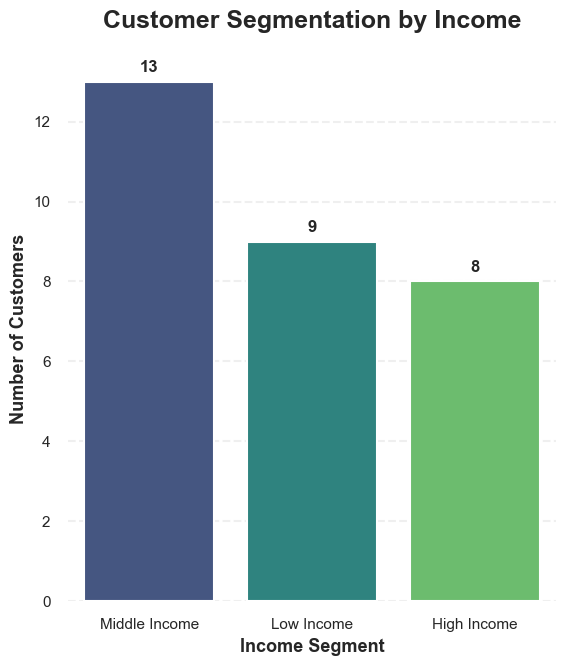

In [168]:
# Set professional style
sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(6, 7))

ax = sns.countplot(
    data=ev_financial,
    x='Income_Segment',
    palette='viridis',
    order=ev_financial['Income_Segment'].value_counts().index
)

# Add count labels above bars
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=12, fontweight='bold')

# Titles and labels
plt.title(
    'Customer Segmentation by Income',
    fontsize=18,
    fontweight='bold',
    pad=20
)

plt.xlabel('Income Segment', fontsize=13, fontweight='bold')
plt.ylabel('Number of Customers', fontsize=13, fontweight='bold')

# Improve appearance
sns.despine(left=True, bottom=True)
plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.grid(axis='x', visible=False)

plt.tight_layout()
plt.show()


### Credit Score-wise Customer Segmentation 💳

In [169]:
ev_financial['Credit_Segment'] = pd.cut(
    ev_financial['Credit_Score'],
    bins=[0, 699, 749, 850],
    labels=['Low Credit', 'Medium Credit', 'High Credit']
)

credit_segment = ev_financial.groupby(
    'Credit_Segment',
    observed=False
).agg(
    Total_Customers=('Application_ID', 'count'),

    Average_Income=('Monthly_Income_INR', 'mean'),

    Average_Loan=('Loan_Amount_INR', 'mean'),

    Average_Credit_Score=('Credit_Score', 'mean')
)

credit_segment

,Total_Customers,Average_Income,Average_Loan,Average_Credit_Score
Credit_Segment,,,,
Low Credit,10,"63,500.00","902,000.00",672.00
Medium Credit,15,"97,600.00","1,258,666.67",722.20
High Credit,5,"124,000.00","1,560,000.00",769.00


C:\Users\AMBIKA\AppData\Local\Temp\ipykernel_13356\3152505624.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


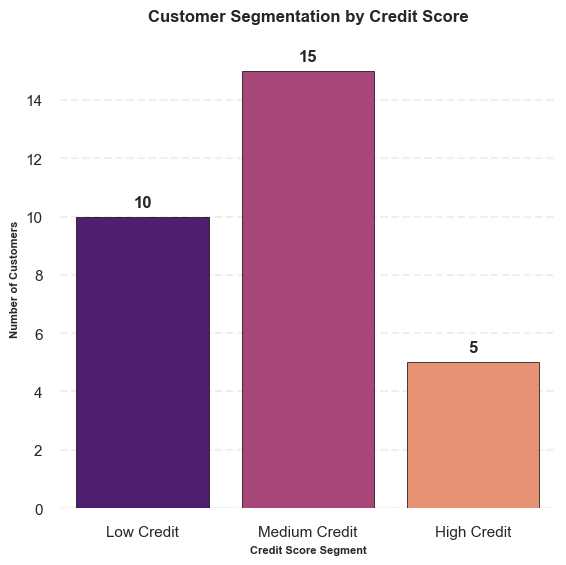

In [170]:

import matplotlib.pyplot as plt
import seaborn as sns

# Set professional theme
sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(6, 6))

ax = sns.barplot(
    x=credit_segment.index,
    y=credit_segment['Total_Customers'],
    palette='magma',
    edgecolor='black',
    linewidth=0.5
)

# Add value labels
for container in ax.containers:
    ax.bar_label(
        container,
        padding=5,
        fontsize=12,
        fontweight='bold'
    )

# Customize title and labels
plt.title(
    'Customer Segmentation by Credit Score',
    fontsize=12,
    fontweight='bold',
    pad=20
)

plt.xlabel('Credit Score Segment', fontsize=8, fontweight='bold')
plt.ylabel('Number of Customers', fontsize=8, fontweight='bold')

# Styling
plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.grid(axis='x', visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


### Employment-wise Customer Segmentation 👨‍💼

In [171]:
employment_segment = ev_financial.groupby(
    'Employment_Type'
).agg(
    Total_Customers=('Application_ID', 'count'),
    Average_Income=('Monthly_Income_INR', 'mean'),
    Average_Loan=('Loan_Amount_INR', 'mean'),
    Average_EMI=('Monthly_EMI_INR', 'mean')
)

employment_segment

,Total_Customers,Average_Income,Average_Loan,Average_EMI
Employment_Type,,,,
Gig Worker,8,"64,500.00","890,000.00","26,118.75"
Private,14,"96,285.71","1,223,571.43","27,707.14"
Self-employed,8,"106,875.00","1,431,250.00","32,006.25"


C:\Users\AMBIKA\AppData\Local\Temp\ipykernel_13356\1308615519.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


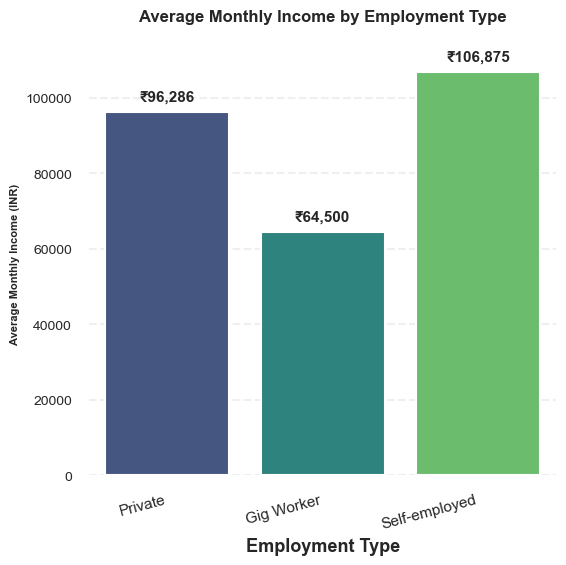

In [172]:

import matplotlib.pyplot as plt
import seaborn as sns

# Professional visualization style
sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(6, 6))

# Create bar chart
ax = sns.barplot(
    data=ev_financial,
    x='Employment_Type',
    y='Monthly_Income_INR',
    estimator='mean',
    palette='viridis',
    errorbar=None,
    edgecolor='white',
    linewidth=1.5
)

# Add income labels above bars
for container in ax.containers:
    labels = [f'₹{bar.get_height():,.0f}' for bar in container]
    ax.bar_label(
        container,
        labels=labels,
        padding=6,
        fontsize=11,
        fontweight='bold'
    )

# Customize title
plt.title(
    'Average Monthly Income by Employment Type',
    fontsize=12,
    fontweight='bold',
    pad=22
)

plt.xlabel('Employment Type', fontsize=13, fontweight='bold')
plt.ylabel('Average Monthly Income (INR)', fontsize=8, fontweight='bold')

# Improve chart appearance
plt.xticks(rotation=15, ha='right', fontsize=11)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.grid(axis='x', visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


### Overall Customer Risk Segmentation 🎯

In [173]:
ev_financial['Customer_Segment'] = np.select(

    [
        (ev_financial['Credit_Score'] < 700) |
        (ev_financial['Prior_Loan_Default_Flag'] == 1),

        (ev_financial['Credit_Score'] >= 750) &
        (ev_financial['Prior_Loan_Default_Flag'] == 0)
    ],

    ['High Risk', 'Low Risk'],

    default='Medium Risk'
)

customer_segment = ev_financial.groupby(
    'Customer_Segment'
).agg(
    Total_Customers=('Application_ID', 'count'),

    Average_Income=('Monthly_Income_INR', 'mean'),

    Average_Credit_Score=('Credit_Score', 'mean'),

    Average_Loan=('Loan_Amount_INR', 'mean'),

    Rejected=('Application_Decision',
              lambda x: (x == 'Rejected').sum())
)

customer_segment

,Total_Customers,Average_Income,Average_Credit_Score,Average_Loan,Rejected
Customer_Segment,,,,,
High Risk,11,"64,636.36",674.55,"915,454.55",3
Low Risk,5,"124,000.00",769.00,"1,560,000.00",0
Medium Risk,14,"99,142.86",723.79,"1,273,571.43",0


C:\Users\AMBIKA\AppData\Local\Temp\ipykernel_13356\2357866023.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


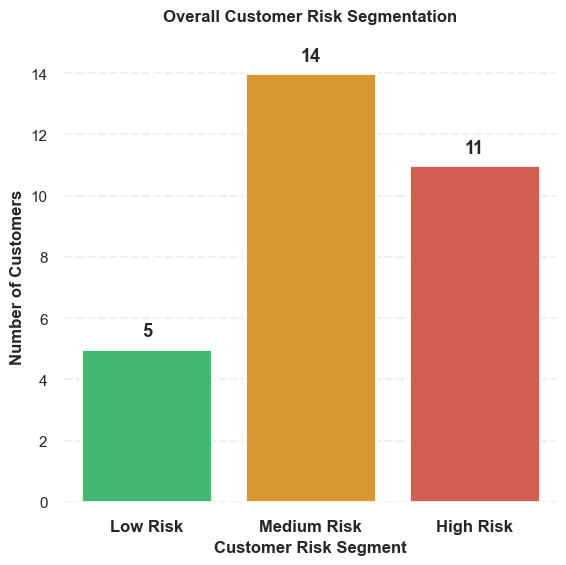

In [174]:

import matplotlib.pyplot as plt
import seaborn as sns

# Professional theme
sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(6, 6))

# Custom risk-based colors
risk_colors = ['#2ECC71', '#F39C12', '#E74C3C']

ax = sns.countplot(
    data=ev_financial,
    x='Customer_Segment',
    order=['Low Risk', 'Medium Risk', 'High Risk'],
    palette=risk_colors,
    edgecolor='white',
    linewidth=2
)

# Add customer count labels
for container in ax.containers:
    ax.bar_label(
        container,
        padding=6,
        fontsize=13,
        fontweight='bold'
    )

# Chart title and labels
plt.title(
    'Overall Customer Risk Segmentation',
    fontsize=12,
    fontweight='bold',
    pad=22
)

plt.xlabel('Customer Risk Segment', fontsize=12, fontweight='bold')
plt.ylabel('Number of Customers', fontsize=12, fontweight='bold')

# Styling
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.grid(axis='x', visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


#### Conclusion: Final Business Insights 💡
project report mein ye points likh sakte hain:
1. Income Segmentation: High Income segment ka average loan amount ₹16.50 lakh hai.
2. Credit Segmentation: Credit score ke basis par customers ko Low, Medium aur High categories mein divide kiya gaya.
3. Employment Segmentation: Private, Self-employed aur Gig Workers ki financial profiles compare ki gayi.
4. Risk Segmentation: 30 customers mein 11 High Risk, 14 Medium Risk aur 5 Low Risk customers identify hue.
5. Business Recommendation: Company ko stronger credit profiles wale customers par focus karna chahiye, jabki high-risk customers ke liye detailed repayment assessment karna chahiye.

### Overall Business Performance Summary 📊

In [175]:
business_summary = {

    'Total_Applications': len(ev_financial),

    'Approved_Applications':
        (ev_financial['Application_Decision'] == 'Approved').sum(),

    'Conditional_Approvals':
        (ev_financial['Application_Decision'] ==
         'Approved with Conditions').sum(),

    'Rejected_Applications':
        (ev_financial['Application_Decision'] == 'Rejected').sum(),

    'Total_Loan_Amount':
        ev_financial['Loan_Amount_INR'].sum(),

    'Average_Loan_Amount':
        ev_financial['Loan_Amount_INR'].mean(),

    'Average_Monthly_Income':
        ev_financial['Monthly_Income_INR'].mean(),

    'Average_EMI':
        ev_financial['Monthly_EMI_INR'].mean()

}

business_summary = pd.Series(business_summary)

print(business_summary)

Total_Applications               30.00
Approved_Applications            21.00
Conditional_Approvals             6.00
Rejected_Applications             3.00
Total_Loan_Amount        35,700,000.00
Average_Loan_Amount       1,190,000.00
Average_Monthly_Income       90,633.33
Average_EMI                  28,430.00
dtype: float64


### Identify Business Problems 🔍
Ab hum apne analysis se business ki major problems identify karenge.

In [176]:
# Create business problem analysis table
business_analysis = pd.DataFrame({
    'No.': [1, 2, 3, 4, 5, 6],

    'Business Problem': [
        'EMI Affordability',
        'Credit Risk',
        'Employment Risk',
        'Previous Default',
        'Regional Performance',
        'Down Payment'
    ],

    'Key Finding': [
        '27 customers have EMI amounts higher than their disposable income.',
        '30% rejection rate in the low credit score group.',
        'Gig workers have a 37.5% loan rejection rate.',
        'Previous defaulters have a 37.5% loan rejection rate.',
        'East region has a 66.7% loan approval rate.',
        'Average down payment ratio is 14.69%.'
    ]
})
business_analysis.style \
    .set_caption("Key Business Problems and Findings") \
    .set_properties(**{
        'text-align': 'left',
        'padding': '12px',
        'border': '1px solid #ddd'
    }) \
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#263B5E'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#263B5E'),
                ('padding', '12px')
            ]
        }
    ])


,No.,Business Problem,Key Finding
0,1,EMI Affordability,27 customers have EMI amounts higher than their disposable income.
1,2,Credit Risk,30% rejection rate in the low credit score group.
2,3,Employment Risk,Gig workers have a 37.5% loan rejection rate.
3,4,Previous Default,Previous defaulters have a 37.5% loan rejection rate.
4,5,Regional Performance,East region has a 66.7% loan approval rate.
5,6,Down Payment,Average down payment ratio is 14.69%.


### Business Recommendations 💡
Ab har problem ke according business recommendation denge.

### 1. Improve EMI Affordability 💳

Problem: 30 mein se 27 customers ki EMI unki disposable income se zyada hai.

Recommendation:
- Customers ki repayment capacity verify karein.
- Lower EMI options offer karein.
- Suitable cases mein loan tenure increase karein.
- Existing financial obligations check karein.
### 2. Improve Credit Risk Management ⚠️

Problem: Low credit score customers ka rejection rate 30% hai.

Recommendation:
- Credit score verification compulsory karein.
- Previous loan defaults check karein.
- High-risk applicants ka additional verification karein.
- Loan approval ke liye risk-based assessment use karein.
### 3. Focus on Customer Segmentation 👥

Problem: Different income aur employment groups ki financial capacity alag hai.

Recommendation:
- High-income customers ke liye suitable premium EV financing plans banayein.
- Salaried customers ko targeted loan offers dein.
- Gig Workers ke liye income stability aur cash-flow verification karein.
- Har customer ki repayment capacity ke according loan amount decide karein.
### 4. Improve Regional Business Performance 🏙️

Problem: East region mein approval rate comparatively low hai.

Recommendation:
- Kolkata mein rejection reasons analyze karein.
- South region mein successful business strategies study karein.
- West region mein higher-value loan opportunities explore karein.
- Low-application cities mein EV financing awareness campaigns chalayein.
### 5. Improve Down Payment Strategy 💰

Problem: Average down payment ratio 14.69% hai.

Recommendation:
- Customers ko higher down payment ke benefits explain karein.
- Different down payment options offer karein.
- Loan amount ko customer ki financial capacity ke according set karein.

### Business Recommendations and Strategic Action Plan

In [177]:

import pandas as pd

# Business Action Plan
action_plan = pd.DataFrame({
    'Priority': [
        'High',
        'High',
        'High',
        'Medium',
        'Medium',
        'Medium'
    ],

    'Action': [
        'EMI Affordability Assessment',
        'Credit Risk Verification',
        'Previous Default Checking',
        'Customer Segmentation',
        'Regional Expansion',
        'Down Payment Strategy'
    ],

    'Reason': [
        'Minimize repayment risk',
        'Reduce loan defaults',
        'Identify risky borrowers',
        'Target the right customers',
        'Find growth opportunities',
        'Reduce financing exposure'
    ]
})

# Display table

action_plan.style \
    .set_caption('Business Action Plan and Priorities') \
    .set_properties(**{
        'text-align': 'left',
        'padding': '12px',
        'border': '1px solid #ddd'
    }) \
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#263B5E'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('padding', '12px')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('font-size', '18px'),
                ('font-weight', 'bold'),
                ('color', '#263B5E'),
                ('padding', '12px')
            ]
        }
    ]) \
    .map(
        lambda x: 'background-color: #FDE2E2; color: #B22222; font-weight: bold'
        if x == 'High' else
        ('background-color: #FFF2CC; color: #996600; font-weight: bold'
         if x == 'Medium' else '')
    , subset=['Priority'])



,Priority,Action,Reason
0,High,EMI Affordability Assessment,Minimize repayment risk
1,High,Credit Risk Verification,Reduce loan defaults
2,High,Previous Default Checking,Identify risky borrowers
3,Medium,Customer Segmentation,Target the right customers
4,Medium,Regional Expansion,Find growth opportunities
5,Medium,Down Payment Strategy,Reduce financing exposure


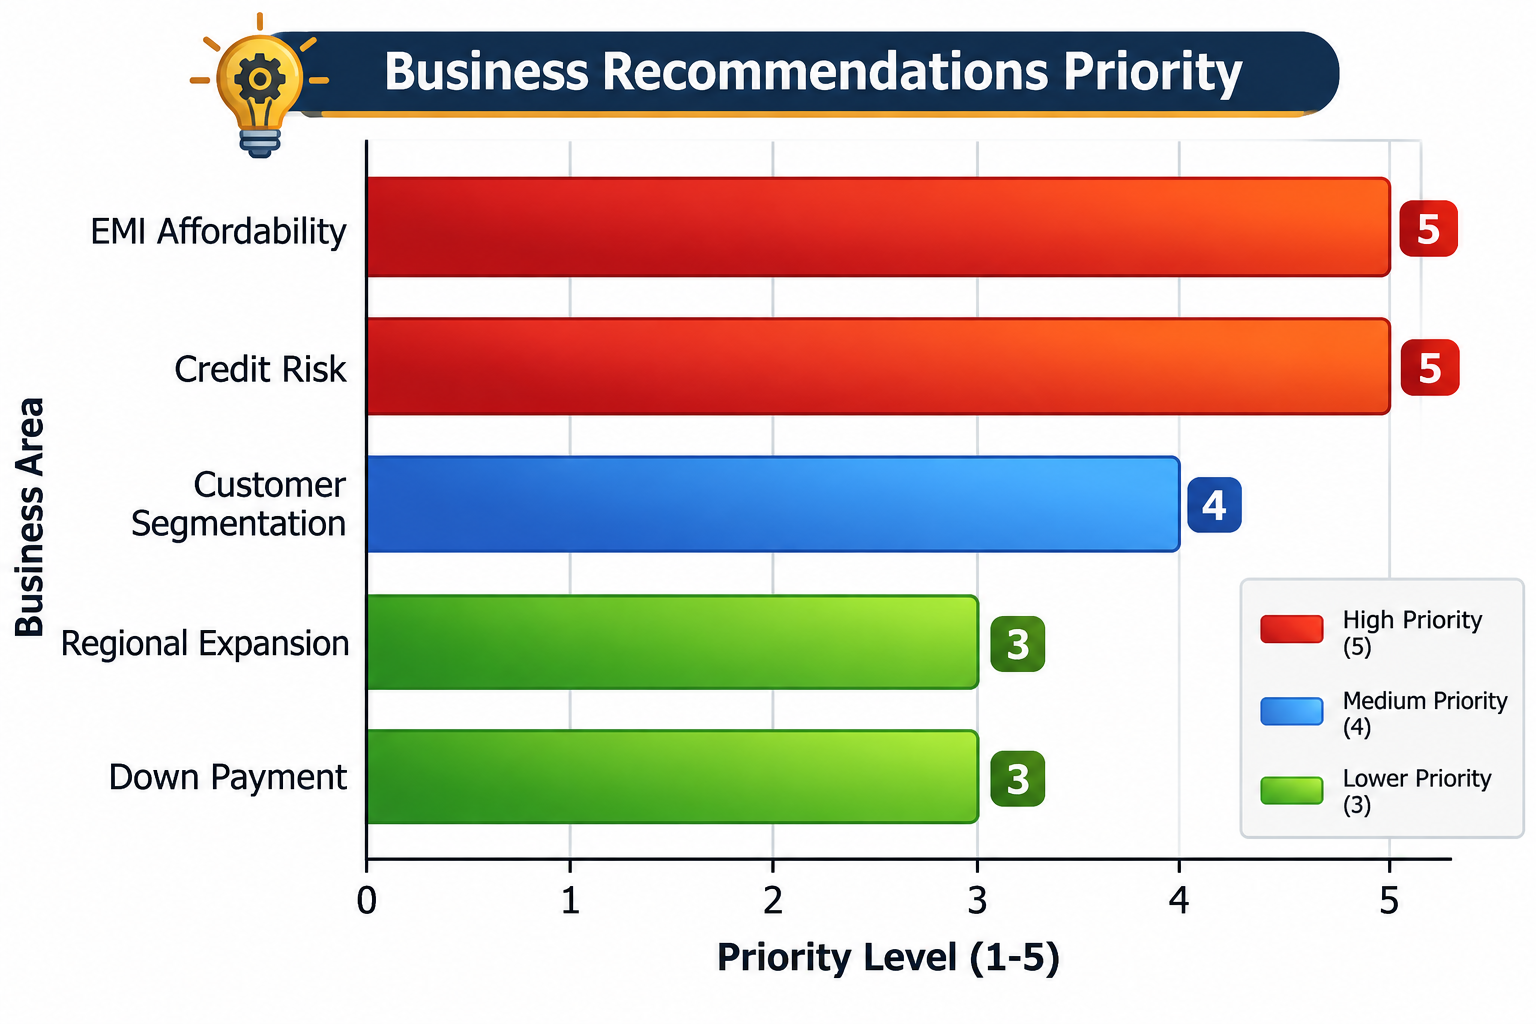
